In [ ]:
!pip install graphviz

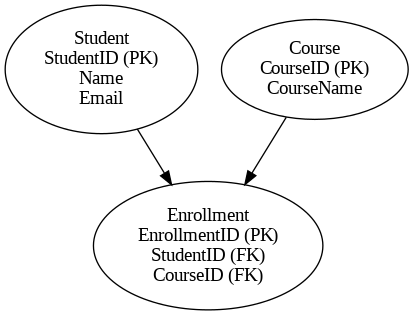

In [ ]:
from graphviz import Digraph
from IPython.display import Image

er = Digraph('ER_Diagram')

er.node('Student', 'Student\nStudentID (PK)\nName\nEmail')
er.node('Course', 'Course\nCourseID (PK)\nCourseName')
er.node('Enrollment', 'Enrollment\nEnrollmentID (PK)\nStudentID (FK)\nCourseID (FK)')

er.edge('Student', 'Enrollment')
er.edge('Course', 'Enrollment')

er.render('er_diagram', format='png', cleanup=True)

Image('er_diagram.png')

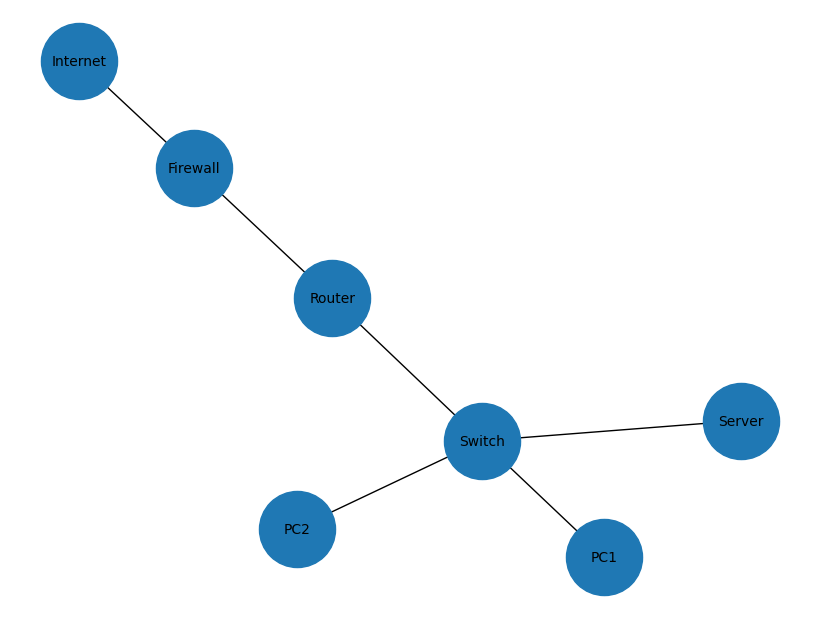

In [ ]:
!pip install networkx matplotlib

import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

G.add_node("Internet")
G.add_node("Firewall")
G.add_node("Router")
G.add_node("Switch")
G.add_node("PC1")
G.add_node("PC2")
G.add_node("Server")

G.add_edges_from([
    ("Internet", "Firewall"),
    ("Firewall", "Router"),
    ("Router", "Switch"),
    ("Switch", "PC1"),
    ("Switch", "PC2"),
    ("Switch", "Server")
])

plt.figure(figsize=(8,6))
nx.draw(
    G,
    with_labels=True,
    node_size=3000,
    font_size=10
)

plt.show()

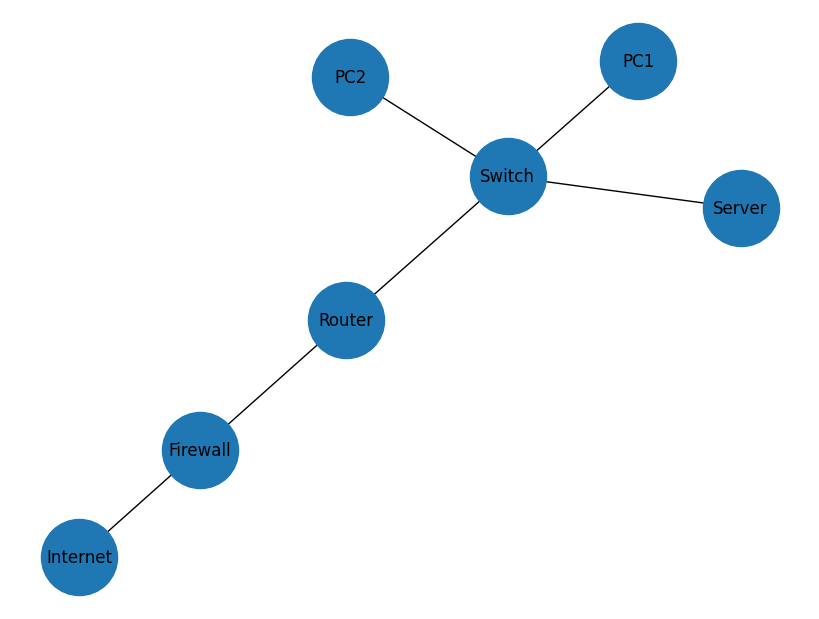

In [ ]:
!pip install networkx matplotlib

import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

G.add_edges_from([
    ("Internet","Firewall"),
    ("Firewall","Router"),
    ("Router","Switch"),
    ("Switch","PC1"),
    ("Switch","PC2"),
    ("Switch","Server")
])

plt.figure(figsize=(8,6))
nx.draw(G, with_labels=True, node_size=3000)

plt.show()

In [ ]:
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())


Nodes: 7
Edges: 6


In [ ]:
path = nx.shortest_path(
    G,
    source="Internet",
    target="Server"
)

print(path)

['Internet', 'Firewall', 'Router', 'Switch', 'Server']


In [ ]:
import turtle

t = turtle.Turtle()
t.circle(50)
turtle.done()

TclError: no display name and no $DISPLAY environment variable

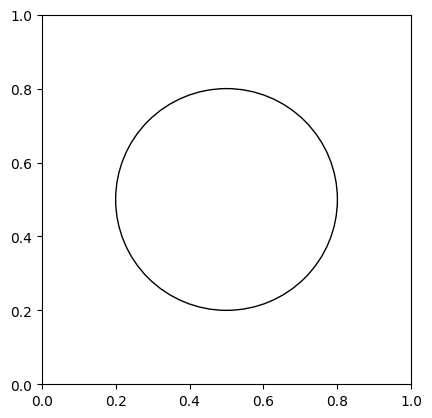

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

circle = plt.Circle((0.5, 0.5), 0.3, fill=False)

ax.add_patch(circle)

ax.set_aspect('equal')
plt.show()

In [ ]:
!nvidia-smi

Fri Jun 12 04:59:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch

print(torch.cuda.is_available())

True


In [ ]:
import torch

print(torch.cuda.get_device_name(0))

Tesla T4


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "Qwen/Qwen2.5-3B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto"
)

print("Model Loaded Successfully")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model Loaded Successfully


In [ ]:
!pip install -q transformers accelerate diffusers sentencepiece
!pip install -q torch torchvision

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "Qwen/Qwen2.5-3B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

llm = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto"
)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

In [ ]:
def ask_llm(prompt):

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(llm.device)

    outputs = llm.generate(
        **inputs,
        max_new_tokens=300
    )

    return tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

In [ ]:
def analyze_character(description):

    prompt = f"""
Extract character information.

Return:

Name
Gender
Appearance
Clothing
Weapons
Abilities
Art Style

Description:
{description}
"""

    return ask_llm(prompt)

In [ ]:
def create_image_prompt(description):

    prompt = f"""
Convert this description into a professional
image generation prompt.

Description:
{description}

Generate a highly detailed prompt.
"""

    return ask_llm(prompt)

In [ ]:
from diffusers import DiffusionPipeline
import torch

pipe = DiffusionPipeline.from_pretrained(
    "black-forest-labs/FLUX.1-schnell",
    torch_dtype=torch.float16
)

pipe.to("cuda")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


GatedRepoError: 401 Client Error. (Request ID: Root=1-6a2f80c4-76d044db563704622738765e;2001491a-2e89-4714-88dc-e39b73e8785c)

Cannot access gated repo for url https://huggingface.co/black-forest-labs/FLUX.1-schnell/resolve/main/model_index.json.
Access to model black-forest-labs/FLUX.1-schnell is restricted. You must have access to it and be authenticated to access it. Please log in.

In [ ]:
from diffusers import AutoPipelineForText2Image
import torch

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sdxl-turbo",
    torch_dtype=torch.float16,
    variant="fp16"
)

pipe.to("cuda")

[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 20.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 3.81 MiB is free. Including non-PyTorch memory, this process has 14.56 GiB memory in use. Of the allocated memory 14.30 GiB is allocated by PyTorch, and 163.91 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
del llm
del tokenizer

import gc
import torch

gc.collect()
torch.cuda.empty_cache()

In [ ]:
torch.cuda.memory_allocated()/1024**3

8.548953533172607

In [ ]:
del llm
del tokenizer

import gc
import torch

gc.collect()
torch.cuda.empty_cache()

print(torch.cuda.memory_allocated()/1024**3)

NameError: name 'llm' is not defined

In [ ]:
print("pipe" in globals())
print("model" in globals())
print("llm" in globals())

True
True
False


In [ ]:
del pipe
del model

import gc
import torch

gc.collect()
torch.cuda.empty_cache()

print("Allocated:",
      torch.cuda.memory_allocated()/1024**3, "GB")

print("Reserved:",
      torch.cuda.memory_reserved()/1024**3, "GB")

Allocated: 0.0 GB
Reserved: 0.0 GB


In [ ]:
if "pipe" in globals():
    del pipe

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

In [ ]:
print(torch.cuda.memory_allocated()/1024**3)

0.0


In [ ]:
from diffusers import AutoPipelineForText2Image
import torch

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=torch.float16
)

pipe.to("cuda")

print("Model Loaded")

model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Model Loaded


  0%|          | 0/1 [00:00<?, ?it/s]

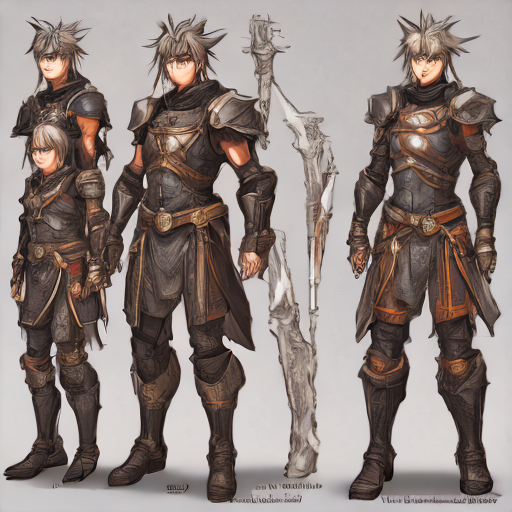

In [ ]:
image = pipe(
    "anime warrior character sheet, full body, concept art",
    num_inference_steps=1,
    guidance_scale=0.0
).images[0]

image

In [ ]:
character = input("Which character would you like me to create?\n")

Which character would you like me to create?
luffy


In [ ]:
def build_prompt(character):

    return f"""
    Professional character design sheet.

    Character:
    {character}

    Show:
    - Front view
    - Side view
    - Back view
    - Equipment details
    - Clean white background
    - Concept art style
    - Character turnaround sheet
    - Highly detailed
    """

  0%|          | 0/4 [00:00<?, ?it/s]

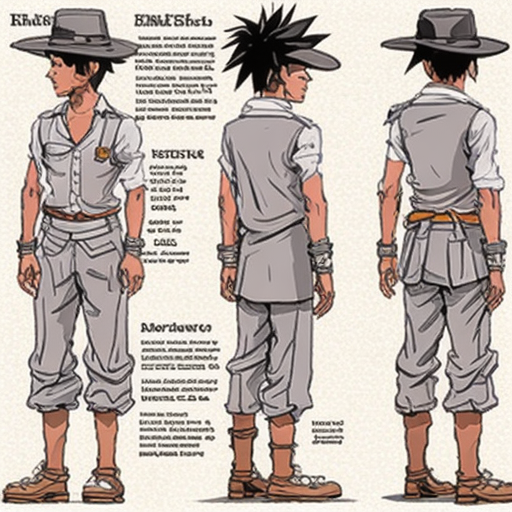

In [ ]:
prompt = build_prompt(character)

image = pipe(
    prompt,
    num_inference_steps=4,
    guidance_scale=0.0
).images[0]

image

In [ ]:
def character_agent(user_character):

    prompt = f"""
    Analyze this character:

    {user_character}

    Create:
    1. Appearance
    2. Clothing
    3. Weapons
    4. Personality
    5. Art Style

    Return a detailed character specification.
    """

    return ask_llm(prompt)

In [ ]:
specification = character_agent(character)

print(specification)

NameError: name 'tokenizer' is not defined

In [ ]:
del model
del pipe

NameError: name 'model' is not defined

In [ ]:
print("pipe" in globals())
print("model" in globals())
print("tokenizer" in globals())

True
False
False


  0%|          | 0/4 [00:00<?, ?it/s]

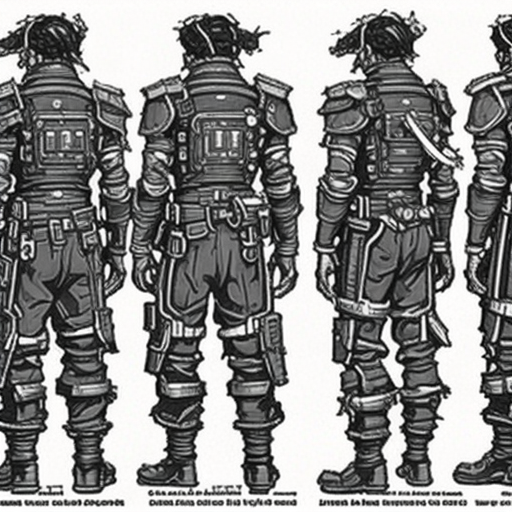

In [ ]:
image = pipe(
    "character design sheet, cyberpunk pirate, front view, side view, back view, concept art",
    num_inference_steps=4,
    guidance_scale=0.0
).images[0]

image


Which character should I create? (type exit to quit)
luffy from one piece


  0%|          | 0/4 [00:00<?, ?it/s]

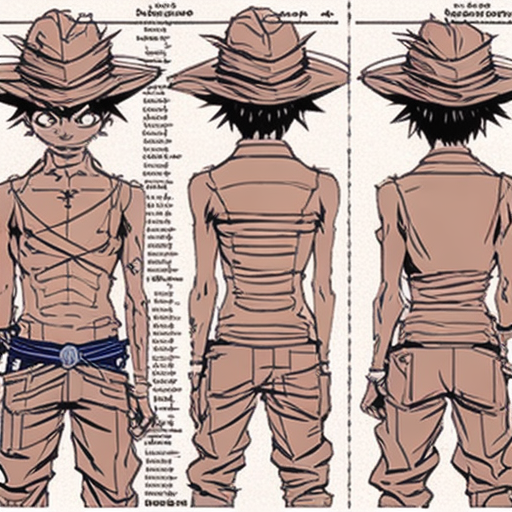


Which character should I create? (type exit to quit)
ace form one piece


  0%|          | 0/4 [00:00<?, ?it/s]

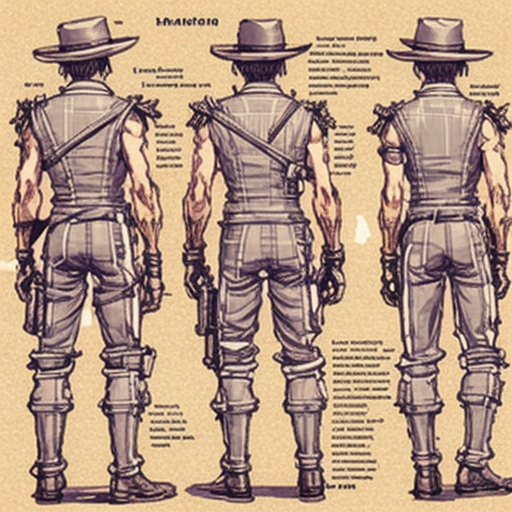


Which character should I create? (type exit to quit)
zoro from one piece


  0%|          | 0/4 [00:00<?, ?it/s]

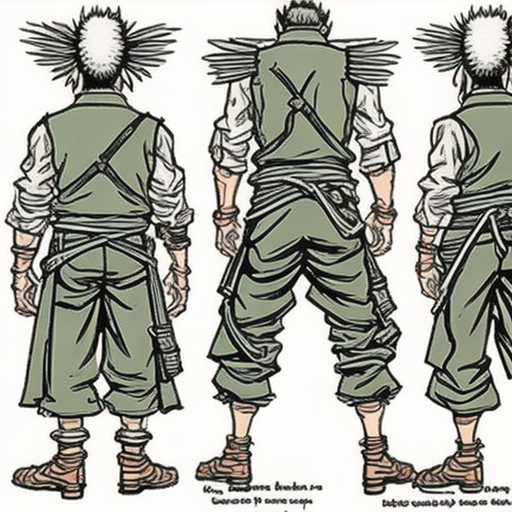


Which character should I create? (type exit to quit)
shinchan


  0%|          | 0/4 [00:00<?, ?it/s]

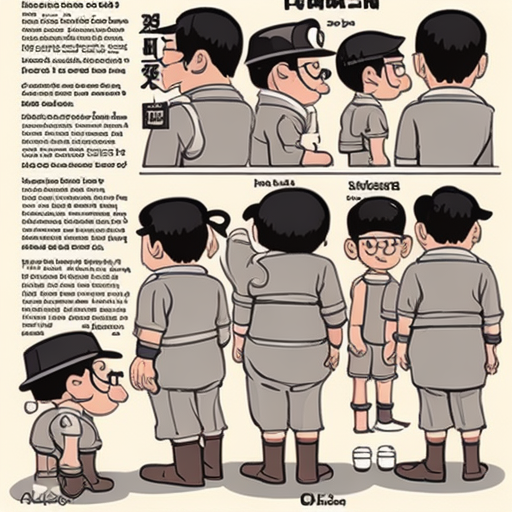


Which character should I create? (type exit to quit)
ace


  0%|          | 0/4 [00:00<?, ?it/s]

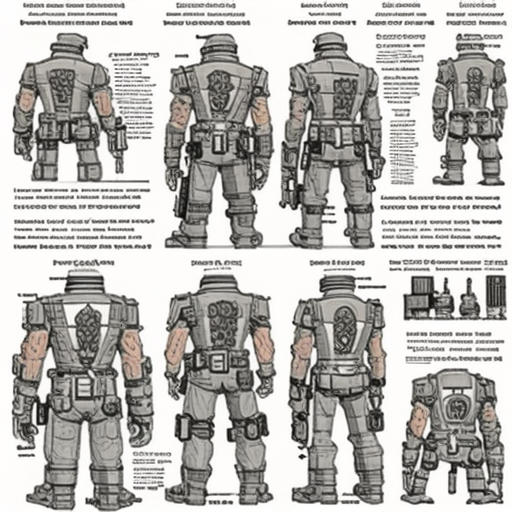


Which character should I create? (type exit to quit)
ace from one piece


  0%|          | 0/4 [00:00<?, ?it/s]

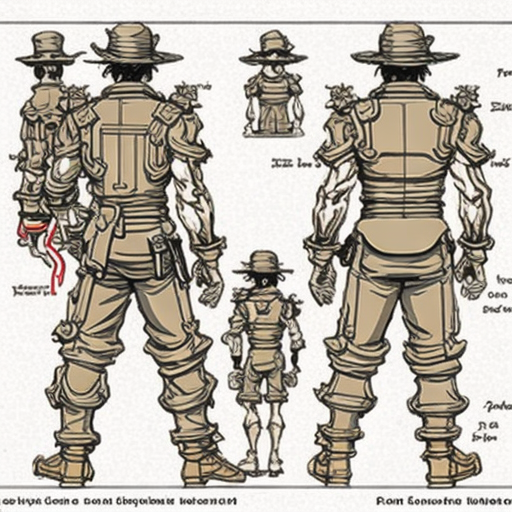

In [ ]:
while True:

    character = input(
        "\nWhich character should I create? (type exit to quit)\n"
    )

    if character.lower() == "exit":
        break

    prompt = f"""
    Professional character design sheet,
    {character},
    front view,
    side view,
    back view,
    turnaround sheet,
    concept art,
    annotations,
    white background,
    highly detailed
    """

    image = pipe(
        prompt,
        num_inference_steps=4,
        guidance_scale=0.0
    ).images[0]

    display(image)